# Tahap 7 — verifikasi preprocessing dengan satu LSTM

Way Urang pilot, development yang sudah digunakan sebelumnya. Semua empat fold tahap6 dipertahankan, test akhir tidak dimuat. Satu LSTM32 + Dense linear; tiga seed tetap, tanpa pencarian arsitektur. Baca ringkasan tahap6 dan diagnosis fold1. Environment terpisah `.venv-lstm`, environment lama tetap.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from lstm_stage7 import Experiment
from IPython.display import display, Markdown, Image
import pandas as pd
from resume_lstm_stage7 import restore_experiment, continue_models
e=restore_experiment()
display(pd.DataFrame(e.plan))
display(pd.DataFrame([e.cfg['environment']]))
print('Fitur sekuens:',e.cfg['sequence_features'])
print('Target scaling:',e.cfg['target_scaling'])
print('Konfigurasi sebelum fit SHA256:',e.config_hash)


Restore tanpa fit. Checkpoint selesai: 28 ; konfigurasi 0d059513ec74bcb5d4a086ac8cae9f93691dabf154250fe97805c56cba6afdfe
Fitur sekuens: ['SO2_origin', 'PM10_lag1', 'PM2.5_lag1', 'CO_lag1', 'O3_lag1', 'NO2_lag1', 'Kec.Angin_lag1', 'Kelembaban_lag1', 'Suhu_lag1', 'Tek.Udara_lag1', 'Sol.Rad_lag1', 'missing_asli_SO2_origin', 'missing_asli_PM10_lag1', 'missing_asli_PM2.5_lag1', 'missing_asli_CO_lag1', 'missing_asli_O3_lag1', 'missing_asli_NO2_lag1', 'missing_asli_Kec.Angin_lag1', 'missing_asli_Kelembaban_lag1', 'missing_asli_Suhu_lag1', 'missing_asli_Tek.Udara_lag1', 'missing_asli_Sol.Rad_lag1']
Target scaling: z=(target-mean_train_bersama_internal)/SDpopulasi_train; MSE training di satuan standar; prediksi di-inverse ke satuan asli sebelum semua skor. Tidak mengisi target.
Konfigurasi sebelum fit SHA256: 0d059513ec74bcb5d4a086ac8cae9f93691dabf154250fe97805c56cba6afdfe


,Fold,Inner train awal,Inner train akhir,Validasi internal awal,Validasi internal akhir,Evaluasi awal,Evaluasi akhir,Slot inner train,Slot internal validation,Slot outer train,Slot evaluasi
0,Fold_01,2025-01-01 00:00:00,2025-04-12 23:30:00,2025-04-13 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00,4896,864,5760,4972
1,Fold_02,2025-01-01 00:00:00,2025-07-10 00:30:00,2025-07-10 01:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00,9122,1610,10732,4971
2,Fold_03,2025-01-01 00:00:00,2025-10-06 01:00:00,2025-10-06 01:30:00,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00,13347,2356,15703,4971
3,Fold_04,2025-01-01 00:00:00,2026-01-02 01:30:00,2026-01-02 02:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00,17572,3102,20674,4971


,python,executable,platform,processor,logical_cpus,cuda_available,torch_cuda_build,versions
0,"3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1...",C:\Users\INTAN\airpollutan_SO2\.venv-lstm\Scri...,Windows-11-10.0.26300-SP0,"Intel64 Family 6 Model 186 Stepping 2, Genuine...",12,False,None,"{'torch': '2.15.0+cpu', 'numpy': '2.5.4', 'pan..."


## Histori kausal dan kecukupan sebelum training

48 langkah origin−47 sampai origin, tanpa kompresi waktu. Imputer hanya prefix train internal, dibekukan sesudahnya. Ffill memakai pengamatan asli sebelumnya maksimum4slot, tanpa fallback. Train dan early stopping menggunakan target asli serta sampel bersama. Scaler11kanal numerik hanya dari slot unik dalam sekuens train internal; indikator missing asli tidak distandardisasi. Target asli distandardisasi untuk MSE memakai parameter train bersama internal, bukan target imputasi. Batas internal dan outer dipurge.

In [2]:
if not getattr(e,'restored',False): e.prepare_all_folds()
display(pd.DataFrame([f.gate for f in e.folds]))
display(pd.DataFrame([r for f in e.folds for r in f.flow]))
display(pd.DataFrame([r for f in e.folds for r in f.distributions]))
display(pd.DataFrame([r for f in e.folds for r in f.losses]))
print('Checkpoint selesai saat resume:',e.fit_count,'; gate awal tersimpan dengan fit_count=0')


Checkpoint selesai saat resume: 28 ; gate awal tersimpan dengan fit_count=0


,Fold,Sampel train bersama,Sampel early stopping bersama,Sampel evaluasi bersama,Lulus,LSTM fit count sebelum gate,Internal train batas eksklusif,Origin purge internal,Target purge internal,Origin purge outer train,Target purge outer train
0,Fold_01,429,668,4619,True,0,2025-04-13 00:00:00,2025-04-12 23:30:00,2025-04-13 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00
1,Fold_02,4253,1463,4729,True,0,2025-07-10 01:00:00,2025-07-10 00:30:00,2025-07-10 01:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00
2,Fold_03,8233,2212,4108,True,0,2025-10-06 01:30:00,2025-10-06 01:00:00,2025-10-06 01:30:00,2025-11-24 03:00:00,2025-11-24 03:30:00
3,Fold_04,12216,2337,3832,True,0,2026-01-02 02:00:00,2026-01-02 01:30:00,2026-01-02 02:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00


,Fold,Bagian,Pipeline,Kandidat origin setelah buffer purge,Target asli teramati,Sekuens finite mandiri,Sampel bersama,Keluar karena irisan,Tidak layak karena sekuens
0,Fold_01,inner_train,P0_median,527,525,525,429,96,0
1,Fold_01,inner_train,P1_ffill_L4,527,525,525,429,96,0
2,Fold_01,inner_train,P2_knn_k10,527,525,429,429,0,96
3,Fold_01,inner_validation,P0_median,864,860,860,668,192,0
4,Fold_01,inner_validation,P1_ffill_L4,864,860,860,668,192,0
5,Fold_01,inner_validation,P2_knn_k10,864,860,668,668,0,192
6,Fold_01,evaluation,P0_median,4972,4890,4890,4619,271,0
7,Fold_01,evaluation,P1_ffill_L4,4972,4890,4786,4619,167,104
8,Fold_01,evaluation,P2_knn_k10,4972,4890,4648,4619,29,242
9,Fold_02,inner_train,P0_median,4753,4668,4668,4253,415,0


,Fold,Bagian,Domain,Awal target,Akhir target,N,Minimum,Median,Maksimum,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,target asli kandidat,2025-04-02 00:30:00,2025-04-12 23:30:00,525,43.53,45.33,47.43,45.350362,0.628458,525
1,Fold_01,inner_train,bersama digunakan,2025-04-02 00:30:00,2025-04-12 23:30:00,429,43.74,45.34,47.23,45.370699,0.618892,429
2,Fold_01,inner_validation,target asli kandidat,2025-04-13 00:00:00,2025-04-30 23:30:00,860,43.72,45.45,47.29,45.436721,0.619540,860
3,Fold_01,inner_validation,bersama digunakan,2025-04-13 00:00:00,2025-04-30 23:30:00,668,43.72,45.45,47.10,45.431347,0.614581,668
4,Fold_01,evaluation,target asli kandidat,2025-05-01 00:00:00,2025-08-12 13:30:00,4890,1.07,43.85,47.81,23.580558,21.929684,2456
5,Fold_01,evaluation,bersama digunakan,2025-05-01 00:00:00,2025-08-12 13:30:00,4619,1.07,44.35,47.81,24.408404,21.911831,2407
6,Fold_02,inner_train,target asli kandidat,2025-04-02 00:30:00,2025-07-10 00:30:00,4668,1.07,45.22,47.81,37.635970,16.753708,3841
7,Fold_02,inner_train,bersama digunakan,2025-04-02 00:30:00,2025-07-10 00:30:00,4253,1.07,45.22,47.81,37.684023,16.716263,3504
8,Fold_02,inner_validation,target asli kandidat,2025-07-10 01:00:00,2025-08-12 13:30:00,1607,1.08,1.56,2.10,1.561133,0.121993,0
9,Fold_02,inner_validation,bersama digunakan,2025-07-10 01:00:00,2025-08-12 13:30:00,1463,1.08,1.56,2.10,1.561476,0.124036,0


,Fold,Bagian,Pipeline,N,Minimum,Median,Maksimum,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,P0_median,96,43.53,45.225,47.43,45.259479,0.665325,96
1,Fold_01,inner_train,P1_ffill_L4,96,43.53,45.225,47.43,45.259479,0.665325,96
2,Fold_01,inner_train,P2_knn_k10,0,NaN,NaN,NaN,NaN,NaN,0
3,Fold_01,inner_validation,P0_median,192,44.01,45.455,47.29,45.455417,0.637778,192
4,Fold_01,inner_validation,P1_ffill_L4,192,44.01,45.455,47.29,45.455417,0.637778,192
5,Fold_01,inner_validation,P2_knn_k10,0,NaN,NaN,NaN,NaN,NaN,0
6,Fold_01,evaluation,P0_median,271,1.16,1.590,46.68,9.470517,16.867851,49
7,Fold_01,evaluation,P1_ffill_L4,167,1.19,1.560,1.99,1.556886,0.101548,0
8,Fold_01,evaluation,P2_knn_k10,29,1.16,1.690,2.04,1.600345,0.181275,0
9,Fold_02,inner_train,P0_median,415,1.16,45.180,47.43,37.143518,17.145549,337


## Model tetap dan early stopping internal

LSTM32 satu layer, output Dense linear, Adam lr0.001, MSE target standar, batch64, maksimal50epoch. Early stopping patience8, min_delta0, pemulihan bobot terbaik. Seed11/23/47. Hidden state dimulai nol untuk tiap sekuens; tidak ada clipping atau fallback. Evaluasi fold hanya setelah pemulihan checkpoint terbaik internal. Prediksi di-inverse ke satuan asli.

In [3]:
continue_models(e)
display(pd.DataFrame(e.training))


Tidak fit ulang: Fold_01
Tidak fit ulang: Fold_02
Tidak fit ulang: Fold_03
Checkpoint dipertahankan: LSTM_P0_median_seed11.pt
Selesai Fold_04 P0_median 11 epoch 36 best 28 fit detik None
Selesai Fold_04 P1_ffill_L4 11 epoch 40 best 32 fit detik 74.07204510000884
Selesai Fold_04 P2_knn_k10 11 epoch 40 best 32 fit detik 85.28829190001125
Selesai Fold_04 P0_median 23 epoch 43 best 35 fit detik 121.693934800016
Selesai Fold_04 P1_ffill_L4 23 epoch 43 best 35 fit detik 114.0970110000053
Selesai Fold_04 P2_knn_k10 23 epoch 43 best 35 fit detik 118.72339169998304
Selesai Fold_04 P0_median 47 epoch 50 best 45 fit detik 815.3856529000041
Selesai Fold_04 P1_ffill_L4 47 epoch 28 best 20 fit detik 26.676432500011288
Selesai Fold_04 P2_knn_k10 47 epoch 28 best 20 fit detik 39.255231299990555


,Fold,Pipeline,Seed,Epoch dijalankan,Epoch terbaik,Internal MSE standar terbaik,Fit dan early stopping detik,Predict detik,N train bersama,N early stopping bersama,Jumlah parameter,Checkpoint SHA256,Resume
0,Fold_01,P0_median,11,11,3,0.998875,3.620310,0.718566,429,668,7201,628cd9960be13c468a16d7e59af6ccd75c8eb83118a9a4...,NaN
1,Fold_01,P1_ffill_L4,11,11,3,0.998693,3.152083,0.713368,429,668,7201,0c06ef6315826f6da1a210b3c164b14f7cec9b30272fdb...,NaN
2,Fold_01,P2_knn_k10,11,11,3,0.998833,3.231418,0.409038,429,668,7201,149c548d9ab36fe4c2a3fab6b0071bbf038de240e0437c...,NaN
3,Fold_01,P0_median,23,15,7,1.004470,3.158361,0.463099,429,668,7201,e3a22f9f0f6432d730f69825b7d3c1f81e70141e869233...,NaN
4,Fold_01,P1_ffill_L4,23,15,7,1.004294,1.976386,0.270002,429,668,7201,03f91dd747719c7c8a4e3fc467212f0e7bbfc98d56e845...,NaN
5,Fold_01,P2_knn_k10,23,15,7,1.004369,1.556889,0.332079,429,668,7201,60039934f2e19032e9d1431a75c11b4cd6b6dea0f73282...,NaN
6,Fold_01,P0_median,47,10,2,0.979408,1.162998,0.226691,429,668,7201,447f264fd5c5476a58e5a0755c1b33657d76336a1a9977...,NaN
7,Fold_01,P1_ffill_L4,47,10,2,0.979357,0.996925,0.287915,429,668,7201,f8970dfe039acb98bab61049e3578b2e632b84bf292cb1...,NaN
8,Fold_01,P2_knn_k10,47,10,2,0.979401,1.330253,0.291804,429,668,7201,030a6b71553843a8a8717ec006c405d57e7570a0885b8e...,NaN
9,Fold_02,P0_median,11,50,45,0.000155,48.568919,0.294959,4253,1463,7201,ed967946dfd6c9877ed3eee9c91fb6c7a2a59e4b388e10...,NaN


## Evaluasi pada target asli dan timestamp bersama

Skor mandiri dan bersama dibedakan. Metrik gabungan dihitung dari seluruh error OOF unik per seed. Prediksi Ridge tersimpan diberi skor ulang pada irisan timestamp yang identik; perbedaan juga mencakup representasi, holdback internal dan optimisasi. Tidak melatih Ridge ulang.

,Fold,Seed,Pipeline,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,11,P0_median,mandiri,4890,4890,100.000000,21.904833,30.694649,21.637427,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,11,P0_median,LSTM bersama,4619,4890,94.458078,21.095355,30.109644,20.816844,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
2,Fold_01,11,P1_ffill_L4,mandiri,4786,4890,97.873211,21.876212,30.674172,21.607414,0,439c2397f3ca65a5659f29396bec05c16f0b3e31c18914...
3,Fold_01,11,P1_ffill_L4,LSTM bersama,4619,4890,94.458078,21.095012,30.109146,20.816496,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
4,Fold_01,11,P2_knn_k10,mandiri,4648,4890,95.051125,21.234027,30.209993,20.957230,0,9b64156964c6fabf370986be859962e7869b38cf3306fe...
...,...,...,...,...,...,...,...,...,...,...,...,...
91,Fold_04,47,P1_ffill_L4,LSTM bersama,3832,4969,77.118132,0.115301,0.151601,0.019998,0,04a8f098fbbf01fe793b35a7e259d3ca5e44c1cbbf045c...
92,Fold_04,47,P2_knn_k10,mandiri,4873,4969,98.068022,0.116862,0.153622,0.020101,0,3fd395291341b6a34009feeb0eff83989be2cbcd928652...
93,Fold_04,47,P2_knn_k10,LSTM bersama,3832,4969,77.118132,0.115462,0.151951,0.021795,0,04a8f098fbbf01fe793b35a7e259d3ca5e44c1cbbf045c...
94,Fold_04,47,Persistence,mandiri,4969,4969,100.000000,0.115935,0.149092,0.000024,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...


,Fold,Seed,Pipeline,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Gabungan_OOF,11,P0_median,mandiri,19797,19797,100.000000,5.514436,15.256124,5.372722,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,11,P0_median,LSTM bersama,17288,19797,87.326363,5.739374,15.564413,5.593709,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
2,Gabungan_OOF,11,P1_ffill_L4,mandiri,17704,19797,89.427691,6.016826,15.949526,5.882846,0,3173a4e2f1104b69c44294c39954f67f91b9e13d323f2d...
3,Gabungan_OOF,11,P1_ffill_L4,LSTM bersama,17288,19797,87.326363,5.739504,15.564159,5.604096,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
4,Gabungan_OOF,11,P2_knn_k10,mandiri,19267,19797,97.322827,5.221807,14.838872,5.089718,0,292941c9b56a79a038b77277ba718173df53f81391a01a...
5,Gabungan_OOF,11,P2_knn_k10,LSTM bersama,17288,19797,87.326363,5.734207,15.564026,5.597114,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
6,Gabungan_OOF,11,Persistence,mandiri,19797,19797,100.000000,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,11,Persistence,LSTM bersama,17288,19797,87.326363,0.216363,0.490766,0.002604,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
8,Gabungan_OOF,23,P0_median,mandiri,19797,19797,100.000000,5.562623,15.376527,5.419069,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
9,Gabungan_OOF,23,P0_median,LSTM bersama,17288,19797,87.326363,5.789708,15.686512,5.638885,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...


,Jenis,Fold,Pipeline,Domain,Seed N,MAE mean seed,MAE SD seed,MAE min seed,MAE max seed,RMSE mean seed,RMSE SD seed,RMSE min seed,RMSE max seed,Bias mean seed,Bias SD seed,Bias min seed,Bias max seed,Cakupan persen mean seed,Cakupan persen SD seed,Cakupan persen min seed,Cakupan persen max seed,N mean seed,N SD seed,N min seed,N max seed,Prediksi negatif mean seed,Prediksi negatif SD seed,Prediksi negatif min seed,Prediksi negatif max seed
0,fold,Fold_01,P0_median,mandiri,3,22.036887,1.177511e-01,21.904833,22.130962,30.881606,0.166466,30.694649,31.013766,21.779476,0.130447,21.637427,21.893895,100.000000,0.0,100.000000,100.000000,4890.0,0.0,4890.0,4890.0,0.0,0.0,0.0,0.0
1,fold,Fold_01,P0_median,LSTM bersama,3,21.221441,1.123622e-01,21.095355,21.310980,30.291595,0.161909,30.109644,30.419786,20.953146,0.125460,20.816844,21.063799,94.458078,0.0,94.458078,94.458078,4619.0,0.0,4619.0,4619.0,0.0,0.0,0.0,0.0
2,fold,Fold_01,P1_ffill_L4,mandiri,3,22.007685,1.170722e-01,21.876212,22.100660,30.860413,0.165618,30.674172,30.991149,21.748762,0.129638,21.607414,21.862118,97.873211,0.0,97.873211,97.873211,4786.0,0.0,4786.0,4786.0,0.0,0.0,0.0,0.0
3,fold,Fold_01,P1_ffill_L4,LSTM bersama,3,21.221250,1.125019e-01,21.095012,21.310914,30.291320,0.162112,30.109146,30.419689,20.952965,0.125611,20.816496,21.063747,94.458078,0.0,94.458078,94.458078,4619.0,0.0,4619.0,4619.0,0.0,0.0,0.0,0.0
4,fold,Fold_01,P2_knn_k10,mandiri,3,21.361552,1.137217e-01,21.234027,21.452437,30.393405,0.163320,30.209993,30.523105,21.094933,0.126780,20.957230,21.206813,95.051125,0.0,95.051125,95.051125,4648.0,0.0,4648.0,4648.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,Ridge identik,Gabungan_OOF,P2_knn_k10,LSTM Ridge bersama,3,5.777604,3.973328e-02,5.734207,5.812198,15.658532,0.084118,15.564026,15.725209,5.639777,0.045968,5.597114,5.688457,87.326363,0.0,87.326363,87.326363,17288.0,0.0,17288.0,17288.0,0.0,0.0,0.0,0.0
71,Ridge identik,Gabungan_OOF,Persistence,LSTM Ridge bersama,3,0.216363,3.399350e-17,0.216363,0.216363,0.490766,0.000000,0.490766,0.490766,0.002604,0.000000,0.002604,0.002604,87.326363,0.0,87.326363,87.326363,17288.0,0.0,17288.0,17288.0,0.0,0.0,0.0,0.0
72,Ridge identik,Gabungan_OOF,Ridge_P0_median,LSTM Ridge bersama,3,4.339720,0.000000e+00,4.339720,4.339720,12.419815,0.000000,12.419815,12.419815,4.095719,0.000000,4.095719,4.095719,87.326363,0.0,87.326363,87.326363,17288.0,0.0,17288.0,17288.0,93.0,0.0,93.0,93.0
73,Ridge identik,Gabungan_OOF,Ridge_P1_ffill_L4,LSTM Ridge bersama,3,4.363958,0.000000e+00,4.363958,4.363958,12.493351,0.000000,12.493351,12.493351,4.142683,0.000000,4.142683,4.142683,87.326363,0.0,87.326363,87.326363,17288.0,0.0,17288.0,17288.0,86.0,0.0,86.0,86.0


,Fold,Seed,Pipeline,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,11,P0_median,LSTM Ridge bersama,4619,4890,94.458078,21.095355,30.109644,20.816844,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
1,Fold_01,11,P1_ffill_L4,LSTM Ridge bersama,4619,4890,94.458078,21.095012,30.109146,20.816496,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
2,Fold_01,11,P2_knn_k10,LSTM Ridge bersama,4619,4890,94.458078,21.094992,30.109118,20.816457,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
3,Fold_01,11,Persistence,LSTM Ridge bersama,4619,4890,94.458078,0.441905,0.905330,0.009820,0,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
4,Fold_01,11,Ridge_P0_median,LSTM Ridge bersama,4619,4890,94.458078,15.907340,24.024782,15.361662,89,0589a89b147f90ec421aa234b734185ffa4d92f41029c7...
...,...,...,...,...,...,...,...,...,...,...,...,...
100,Gabungan_OOF,47,P2_knn_k10,LSTM Ridge bersama,17288,19797,87.326363,5.812198,15.725209,5.688457,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
101,Gabungan_OOF,47,Persistence,LSTM Ridge bersama,17288,19797,87.326363,0.216363,0.490766,0.002604,0,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
102,Gabungan_OOF,47,Ridge_P0_median,LSTM Ridge bersama,17288,19797,87.326363,4.339720,12.419815,4.095719,93,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...
103,Gabungan_OOF,47,Ridge_P1_ffill_L4,LSTM Ridge bersama,17288,19797,87.326363,4.363958,12.493351,4.142683,86,ca8fc74b754281dd5a4dd774f07fbce5a510d5be10d7d8...


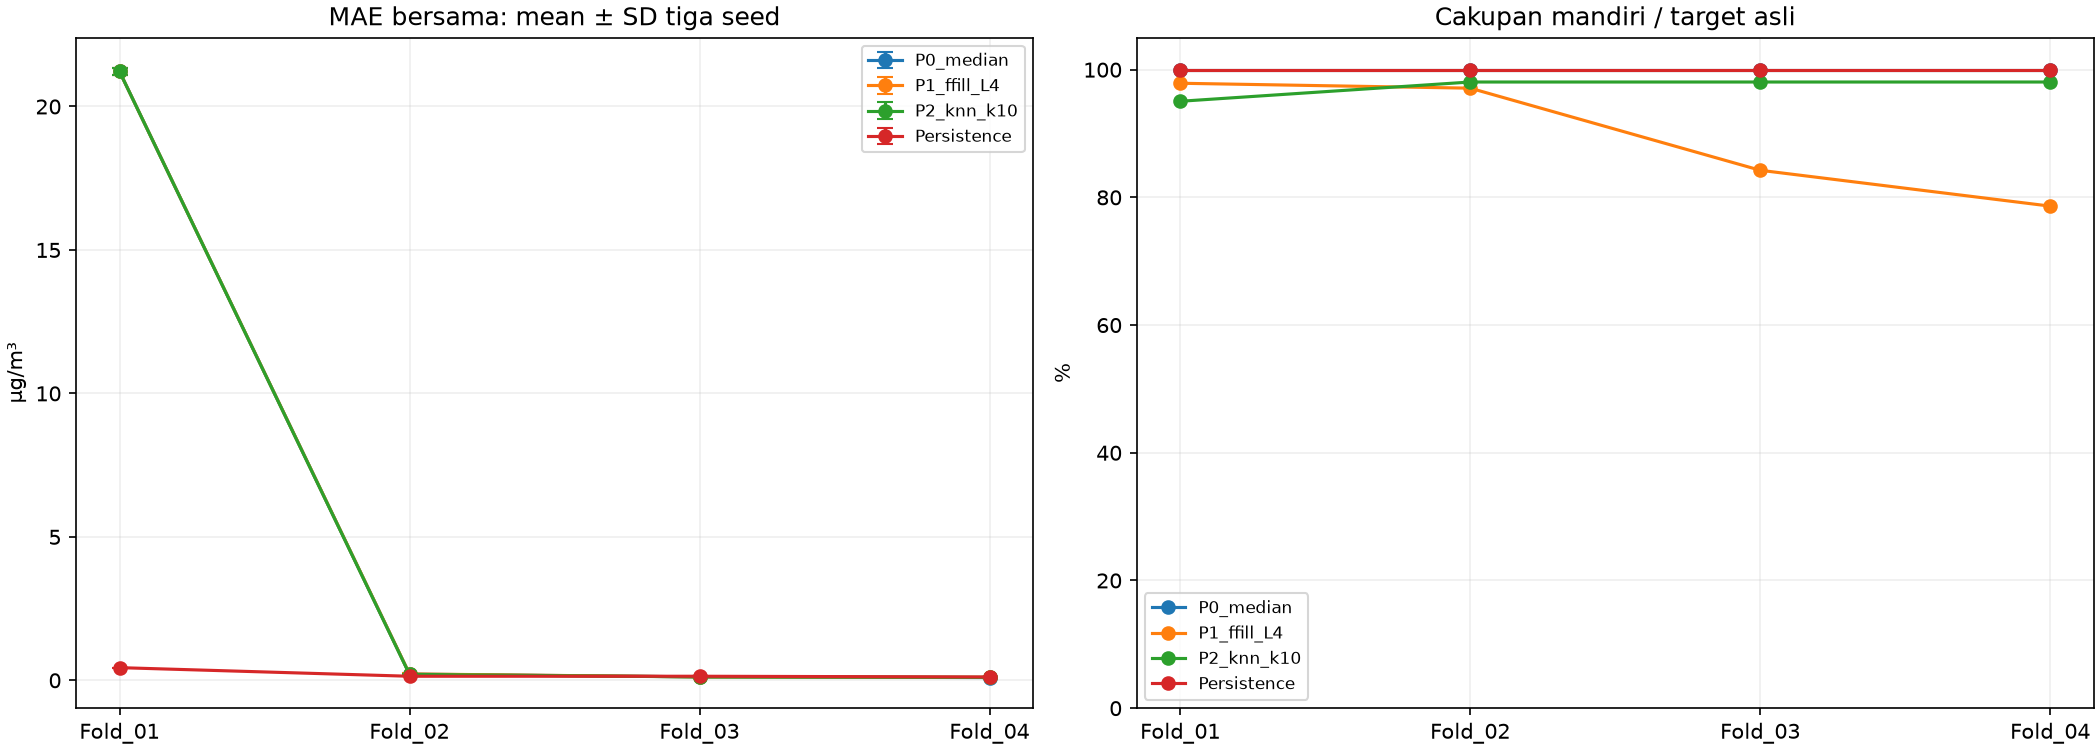

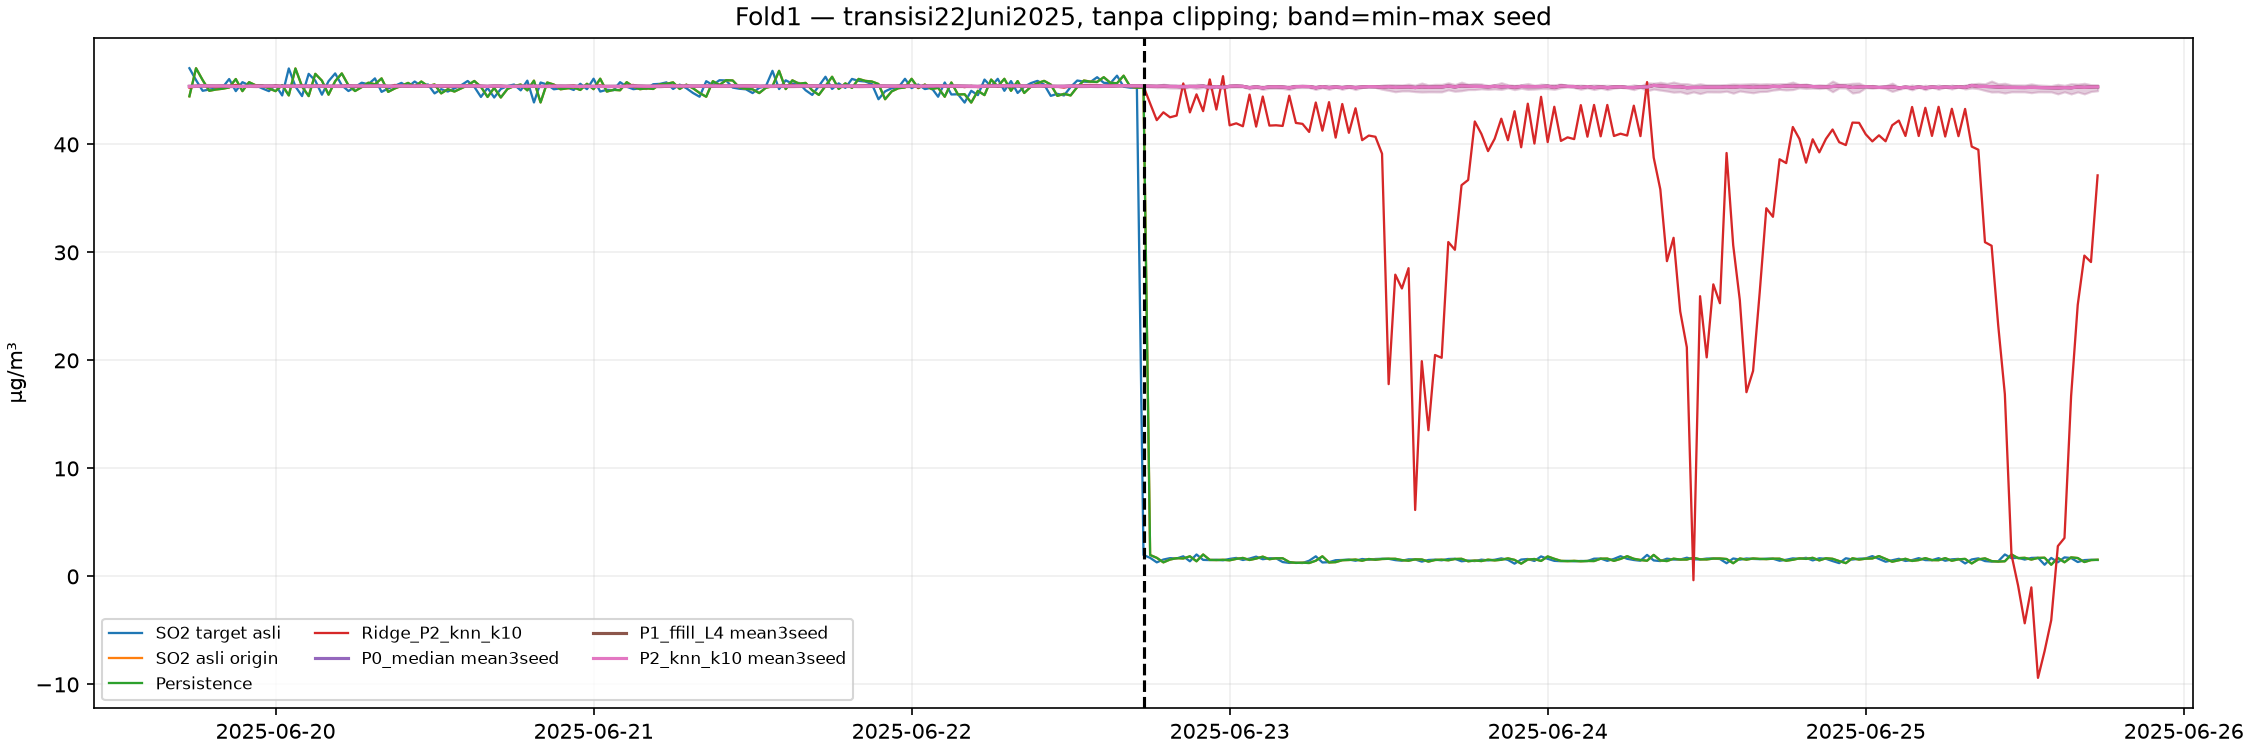

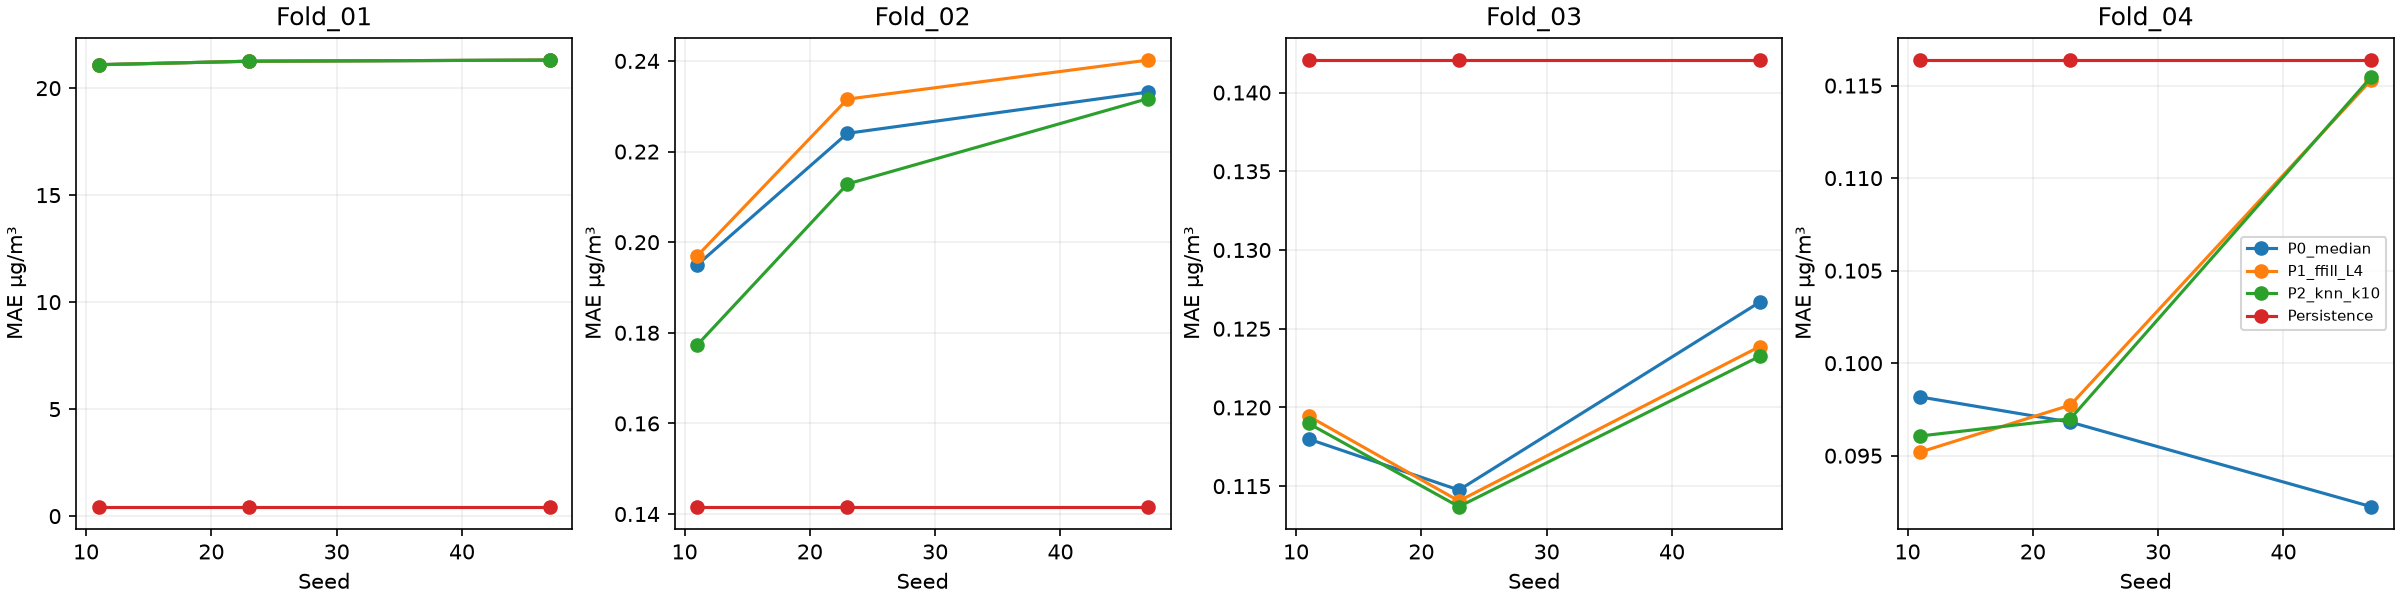

In [4]:
e.summarize()
display(pd.DataFrame(e.metrics))
display(pd.DataFrame(e.pooled))
display(pd.DataFrame(e.variation))
display(pd.DataFrame(e.ridge_comparison))
for name in ['mae_cakupan_fold.png','transisi_fold1.png','mae_antar_seed.png']:
    display(Image(filename=str(ROOT/'outputs/figures/lstm_preprocessing'/name)))


In [5]:
e.export_excel()
display(Markdown((ROOT/'outputs/ringkasan_lstm_preprocessing.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Seed","Pipeline","Domain","N","Denominator target asli"],["Gabungan_OOF",11,"P0_median","mandiri",19797,19797],["Gabungan_OOF",11,"P0_median","LSTM bersama",17288,19797],["Gabungan_OOF",11,"P1_ffill_L4","mandiri",17704,19797]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\hasil_lstm_preprocessing.xlsx.inspect.ndjson
Ekspor selesai: 28 sheet.



# Tahap 7 — verifikasi preprocessing dengan satu LSTM Way Urang

**Validasi pengembangan**, bukan pengujian independen: development train+validasi lama sudah digunakan dalam eksperimen sebelumnya. Semua empat fold tahap6 termasuk fold pertama dipertahankan. Test akhir mulai2026-06-19 06:30 tidak dimuat, ditransformasi atau dievaluasi. Tidak ada pencarian arsitektur/parameter terbaik. Way Urang masih pilot sementara.

## Lingkungan

Environment lama `.venv` menggunakan Python3.15.2 tanpa framework. Dibuat `.venv-lstm` terpisah dengan Python3.12.14, tanpa mengubah environment lama atau dependensinya. PyTorchCPU resmi dipasang setelah pemeriksaan kompatibilitas; environment Python3.12 didukung pada Windows menurut [dokumentasi PyTorch](https://pytorch.org/get-started/locally/).

Python: 3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]. Executable: `C:\Users\INTAN\airpollutan_SO2\.venv-lstm\Scripts\python.exe`. Platform: Windows-11-10.0.26300-SP0. CPU: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel; logicalCPU=12. Perangkat pelatihan **CPU satu thread**, deterministic algorithms=True; CUDA tersedia=False, CUDA build=None. GPU tidak digunakan. Pemeriksaan Win32/CIM tidak diberi akses; identitas CPU memakai informasi proses/OS, bukan inventaris hardware penuh.

| Dependensi | Versi |
|---|---|
| torch | 2.15.0+cpu |
| numpy | 2.5.4 |
| pandas | 3.1.1 |
| scikit-learn | 1.9.1 |
| scipy | 1.18.1 |
| matplotlib | 3.11.2 |
| ipykernel | 7.4.0 |

Lock dependensi lengkap ada pada `requirements-lstm-lock.txt` di akar proyek; torch berasal dari indexCPU resmi `https://download.pytorch.org/whl/cpu`. Kernel `so2-lstm` terpasang pada prefix environment baru. Tidak ada lingkungan sebelumnya dihapus.

## Rancangan dikunci sebelum training

SHA256 konfigurasi: 0d059513ec74bcb5d4a086ac8cae9f93691dabf154250fe97805c56cba6afdfe. Konfigurasi dan rencana fold disimpan sebelum preprocessing/model; semua gate dihitung ketika jumlahfitLSTM=0.

Konfigurasi terkunci juga membawa metadata Ridge tahap6 sebagai konteks. Field lama `so2_lags`, `missing_indicators` (17 indikator Ridge), `ridge_scaler`, serta aturan train/validasi Ridge tidak menentukan kanal atau fitting LSTM. Spesifikasi operasional LSTM adalah `sequence_features` (11numerik+11 indikator), `feature_scaling`, `target_scaling`, `internal_split` dan `imputer_fit_scope`. Lingkup setiapfield ditandai pada workbook dan `klarifikasi_lingkup_konfigurasi.json`; konfigurasi sebelumfit tidak ditulis ulang dan tidak ada parameter pelaksanaan diubah.

| Fold | Inner train awal | Inner train akhir | Validasi internal awal | Validasi internal akhir | Evaluasi awal | Evaluasi akhir |
|---|---|---|---|---|---|---|
| Fold_01 | 2025-01-01 00:00:00 | 2025-04-12 23:30:00 | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 |
| Fold_02 | 2025-01-01 00:00:00 | 2025-07-10 00:30:00 | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 |
| Fold_03 | 2025-01-01 00:00:00 | 2025-10-06 01:00:00 | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 |
| Fold_04 | 2025-01-01 00:00:00 | 2026-01-02 01:30:00 | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 |

Batas internal= floor(0,85×jumlahslot outer train); 15%akhir kalender untuk early stopping. Seluruh timestamp outerfold sama persis dengan tahap6. Kalibrasi90 hari awal inner train, prefix update30 hari, buffer48 slot tetap; tidak disesuaikan menurut skor. Train model berakhir pada origin yang targetnya masih berada dalam inner train. Origin yang targetnya menyeberang batas internal dipindahkan ke bagian validasi internal, bukan dipakai melatih. Aturan sama pada batas outer. Konteks historis sebelum batas validasi digunakan karena sudah tersedia saat origin.

| Fold | Sampel train bersama | Sampel early stopping bersama | Sampel evaluasi bersama | Lulus | LSTM fit count sebelum gate |
|---|---|---|---|---|---|
| Fold_01 | 429 | 668 | 4619 | True | 0 |
| Fold_02 | 4253 | 1463 | 4729 | True | 0 |
| Fold_03 | 8233 | 2212 | 4108 | True | 0 |
| Fold_04 | 12216 | 2337 | 3832 | True | 0 |

Gate ≥64 sampel train, ≥1 sampel validasi internal dan evaluasi hanya pemeriksaan kelayakan komputasional, bukan jaminan generalisasi. fold 1 tersisa429 sampel train; distribusi sempit akibat kalibrasi dan holdback internal tetap dilaporkan.

## Fitur sekuens dan kausalitas

Setiap sampel memuat **48 langkah berurutan dari origin−47 sampai origin**, termasuk origin, interval30menit. Ini48 slot dengan bentang timestamp23,5jam. Horizon target=origin+30menit. Tidak memampatkan waktu dengan menghapus slot kosong.

| Urutan | Fitur |
|---|---|
| 0 | SO2_origin |
| 1 | PM10_lag1 |
| 2 | PM2.5_lag1 |
| 3 | CO_lag1 |
| 4 | O3_lag1 |
| 5 | NO2_lag1 |
| 6 | Kec.Angin_lag1 |
| 7 | Kelembaban_lag1 |
| 8 | Suhu_lag1 |
| 9 | Tek.Udara_lag1 |
| 10 | Sol.Rad_lag1 |
| 11 | missing_asli_SO2_origin |
| 12 | missing_asli_PM10_lag1 |
| 13 | missing_asli_PM2.5_lag1 |
| 14 | missing_asli_CO_lag1 |
| 15 | missing_asli_O3_lag1 |
| 16 | missing_asli_NO2_lag1 |
| 17 | missing_asli_Kec.Angin_lag1 |
| 18 | missing_asli_Kelembaban_lag1 |
| 19 | missing_asli_Suhu_lag1 |
| 20 | missing_asli_Tek.Udara_lag1 |
| 21 | missing_asli_Sol.Rad_lag1 |

Sebelas kanal numerik adalah SO₂(t) dan sepuluh kovariat(t−1 slot); sebelas kanal lain adalah missing asli sebelum imputasi pada setiap langkah. CurahHujan dan seluruh turunannya tidak dipakai. Lag tabular Ridge0/1/2/6/12/24/48 tidak diduplikasi ke tiap langkah. SO₂ terakhir diasumsikan sudah tersedia saat origin, kovariat dengan keterlambatan30menit; latensi aktual belum dikonfirmasi. Tidak menggunakan arah angin linear atau timestamp sebagai angka mentah.

P0 median prefix inner train; P1 pengamatanasli sebelumnya maksimum4 slot, tanpa fallback, dan hasil imputasi tidak mereset umur donor; P2 KNN k10, distanceweighting, nan-euclidean, scaler prefixtrain, donor ber-SO₂ asli dan minimaldua kovariat asli. Imputer dibuat baru per fold. Setelah inner train, parameter median/scalerKNN dan bankdonor KNN dibekukan untuk validasi internal serta evaluasiouter. Ffill boleh memakai original terdahulu yang baru tersedia, sesuai aturan online sebelumnya. Tidak memakai SO₂ masa depan, backwardfill, interpolasi dua arah atau rollingberpusat.

Scaler input LSTM di-fit pada **slot input unik** yang tercakup sekuens train internal bersama: sebelas kanal numerik StandardScaler, indikator tetap0/1. Target train asli distandardisasi memakai mean danSDpopulasi target train internal bersama, aturan tetap sebelumfit demi skala optimisasi antar-fold. MSE training di satuan target standar; semua prediksi di-inverse sebelum MAE/RMSE/bias pada satuan asli. Tidak ada target kosong yang diisi. Histori, nilai asli dan penanda missing tersimpan untuk pelacakan; nol/lonjakan/konstan/ekstrem tidak dibuang.

## Model dan early stopping

Satu LSTM32unit satu layer, unidirectional, hiddenstate awalnol tiap sekuens, tanpa dropout; Dense linear1output, total7.201 parameter. Adam learning rate 0.001, betas0.9/0.999, eps1e−8, weight decay 0; batch64, maksimal50 epoch. Earlystopping patience 8, min_delta 0, checkpoint best internal MSE dipulihkan. Tidak ada scheduler, gradientclipping atau clippingprediksi. Seed11/23/47; bobot awal dan urutan minibatch identik antar-pipeline untuk seed sama. Tidak menggunakan evaluasiouter untuk pemilihan epoch.

| Fold | Pipeline | Seed | Epoch dijalankan | Epoch terbaik | Internal MSE standar terbaik | Fit dan early stopping detik | Predict detik |
|---|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 11 | 11 | 3 | 1.00 | 3.620310 | 0.718566 |
| Fold_01 | P1_ffill_L4 | 11 | 11 | 3 | 1.00 | 3.152083 | 0.713368 |
| Fold_01 | P2_knn_k10 | 11 | 11 | 3 | 1.00 | 3.231418 | 0.409038 |
| Fold_01 | P0_median | 23 | 15 | 7 | 1.00 | 3.158361 | 0.463099 |
| Fold_01 | P1_ffill_L4 | 23 | 15 | 7 | 1.00 | 1.976386 | 0.270002 |
| Fold_01 | P2_knn_k10 | 23 | 15 | 7 | 1.00 | 1.556889 | 0.332079 |
| Fold_01 | P0_median | 47 | 10 | 2 | 0.98 | 1.162998 | 0.226691 |
| Fold_01 | P1_ffill_L4 | 47 | 10 | 2 | 0.98 | 0.996925 | 0.287915 |
| Fold_01 | P2_knn_k10 | 47 | 10 | 2 | 0.98 | 1.330253 | 0.291804 |
| Fold_02 | P0_median | 11 | 50 | 45 | 0.00 | 48.568919 | 0.294959 |
| Fold_02 | P1_ffill_L4 | 11 | 50 | 45 | 0.00 | 55.098385 | 0.169748 |
| Fold_02 | P2_knn_k10 | 11 | 50 | 45 | 0.00 | 54.107953 | 0.295580 |
| Fold_02 | P0_median | 23 | 50 | 48 | 0.00 | 44.406729 | 0.271943 |
| Fold_02 | P1_ffill_L4 | 23 | 50 | 48 | 0.00 | 47.155454 | 0.364824 |
| Fold_02 | P2_knn_k10 | 23 | 50 | 48 | 0.00 | 82.430978 | 0.637316 |
| Fold_02 | P0_median | 47 | 50 | 44 | 0.00 | 48.297897 | 0.239861 |
| Fold_02 | P1_ffill_L4 | 47 | 50 | 44 | 0.00 | 39.168654 | 0.295579 |
| Fold_02 | P2_knn_k10 | 47 | 50 | 44 | 0.00 | 40.599672 | 0.171047 |
| Fold_03 | P0_median | 11 | 50 | 48 | 0.00 | 76.562502 | 0.247312 |
| Fold_03 | P1_ffill_L4 | 11 | 50 | 50 | 0.00 | 75.942441 | 0.185829 |
| Fold_03 | P2_knn_k10 | 11 | 50 | 50 | 0.00 | 83.576186 | 0.263848 |
| Fold_03 | P0_median | 23 | 50 | 50 | 0.00 | 83.287150 | 0.197166 |
| Fold_03 | P1_ffill_L4 | 23 | 50 | 50 | 0.00 | 78.504728 | 0.152327 |
| Fold_03 | P2_knn_k10 | 23 | 50 | 50 | 0.00 | 76.603617 | 0.201387 |
| Fold_03 | P0_median | 47 | 50 | 50 | 0.00 | 80.248087 | 0.247381 |
| Fold_03 | P1_ffill_L4 | 47 | 50 | 50 | 0.00 | 82.057616 | 0.116939 |
| Fold_03 | P2_knn_k10 | 47 | 50 | 50 | 0.00 | 66.593370 | 0.184023 |
| Fold_04 | P0_median | 11 | 36 | 28 | 0.00 | — | 0.279061 |
| Fold_04 | P1_ffill_L4 | 11 | 40 | 32 | 0.00 | 74.072045 | 0.137144 |
| Fold_04 | P2_knn_k10 | 11 | 40 | 32 | 0.00 | 85.288292 | 0.324280 |
| Fold_04 | P0_median | 23 | 43 | 35 | 0.00 | 121.693935 | 0.260642 |
| Fold_04 | P1_ffill_L4 | 23 | 43 | 35 | 0.00 | 114.097011 | 0.252240 |
| Fold_04 | P2_knn_k10 | 23 | 43 | 35 | 0.00 | 118.723392 | 0.274158 |
| Fold_04 | P0_median | 47 | 50 | 45 | 0.00 | 815.385653 | 0.083429 |
| Fold_04 | P1_ffill_L4 | 47 | 28 | 20 | 0.00 | 26.676433 | 0.065949 |
| Fold_04 | P2_knn_k10 | 47 | 28 | 20 | 0.00 | 39.255231 | 0.164350 |

Riwayat loss setiap epoch dan checkpoint bobot terbaik tersimpan per fold/pipeline/seed. Parameter dibangun ulang dari nol setiapfit, tanpa fine-tune/reuse antar-fold.

Sebanyak 19 dari36 kombinasi mencapai batas50 epoch; 8 memiliki bobot terbaik pada epoch50. Mencapai batas anggaran ini bukan bukti konvergensi. Jumlah epoch dan patience tidak ditambah untuk mengejar skor evaluasi.

## Sampel bersama dan distribusi target

Seluruh target asli pada bagian kalender, sebelum pengurangan kalibrasi/buffer atau irisan:

| Fold | Bagian | Awal target kalender | Akhir target kalender | Slot kalender | N | Minimum | Median | Maksimum |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | 2025-01-01 00:00:00 | 2025-04-12 23:30:00 | 4896 | 3064 | 0.92 | 44.97 | 80.71 |
| Fold_01 | inner_validation | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 864 | 860 | 43.72 | 45.45 | 47.29 |
| Fold_01 | evaluation | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 4972 | 4890 | 1.07 | 43.85 | 47.81 |
| Fold_02 | inner_train | 2025-01-01 00:00:00 | 2025-07-10 00:30:00 | 9122 | 7207 | 0.92 | 45.12 | 80.71 |
| Fold_02 | inner_validation | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 1610 | 1607 | 1.08 | 1.56 | 2.10 |
| Fold_02 | evaluation | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 4971 | 4969 | 1.04 | 1.56 | 2.14 |
| Fold_03 | inner_train | 2025-01-01 00:00:00 | 2025-10-06 01:00:00 | 13347 | 11427 | 0.92 | 1.73 | 80.71 |
| Fold_03 | inner_validation | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2356 | 2356 | 1.04 | 1.56 | 2.07 |
| Fold_03 | evaluation | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 4971 | 4969 | 1.08 | 1.56 | 2.04 |
| Fold_04 | inner_train | 2025-01-01 00:00:00 | 2026-01-02 01:30:00 | 17572 | 15652 | 0.92 | 1.64 | 80.71 |
| Fold_04 | inner_validation | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 3102 | 3100 | 1.08 | 1.56 | 2.04 |
| Fold_04 | evaluation | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 4971 | 4969 | 1.09 | 1.56 | 2.06 |

Target asli yang benar-benar dipakai pada cohort bersama:

| Fold | Bagian | Awal target | Akhir target | N | Minimum | Median | Maksimum | SO2 lebih2.14 |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | 2025-04-02 00:30:00 | 2025-04-12 23:30:00 | 429 | 43.74 | 45.34 | 47.23 | 429 |
| Fold_01 | inner_validation | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 668 | 43.72 | 45.45 | 47.10 | 668 |
| Fold_01 | evaluation | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 4619 | 1.07 | 44.35 | 47.81 | 2407 |
| Fold_02 | inner_train | 2025-04-02 00:30:00 | 2025-07-10 00:30:00 | 4253 | 1.07 | 45.22 | 47.81 | 3504 |
| Fold_02 | inner_validation | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 1463 | 1.08 | 1.56 | 2.10 | 0 |
| Fold_02 | evaluation | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 4729 | 1.04 | 1.56 | 2.14 | 0 |
| Fold_03 | inner_train | 2025-04-02 00:30:00 | 2025-10-06 01:00:00 | 8233 | 1.04 | 1.68 | 47.81 | 3504 |
| Fold_03 | inner_validation | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2212 | 1.04 | 1.56 | 2.07 | 0 |
| Fold_03 | evaluation | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 4108 | 1.08 | 1.56 | 2.04 | 0 |
| Fold_04 | inner_train | 2025-04-02 00:30:00 | 2026-01-02 01:30:00 | 12216 | 1.04 | 1.62 | 47.81 | 3504 |
| Fold_04 | inner_validation | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 2337 | 1.08 | 1.56 | 2.04 | 0 |
| Fold_04 | evaluation | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 3832 | 1.09 | 1.56 | 2.06 | 0 |

Angka2,14 hanya penelusur hasil lama, bukan ambang kualitas/bahaya. Workbook melaporkan targetkandidat sebelum irisan dan distribusi bulanan.

| Fold | Bagian | Pipeline | Kandidat origin setelah buffer purge | Target asli teramati | Sekuens finite mandiri | Sampel bersama | Keluar karena irisan |
|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | P0_median | 527 | 525 | 525 | 429 | 96 |
| Fold_01 | inner_train | P1_ffill_L4 | 527 | 525 | 525 | 429 | 96 |
| Fold_01 | inner_train | P2_knn_k10 | 527 | 525 | 429 | 429 | 0 |
| Fold_01 | inner_validation | P0_median | 864 | 860 | 860 | 668 | 192 |
| Fold_01 | inner_validation | P1_ffill_L4 | 864 | 860 | 860 | 668 | 192 |
| Fold_01 | inner_validation | P2_knn_k10 | 864 | 860 | 668 | 668 | 0 |
| Fold_01 | evaluation | P0_median | 4972 | 4890 | 4890 | 4619 | 271 |
| Fold_01 | evaluation | P1_ffill_L4 | 4972 | 4890 | 4786 | 4619 | 167 |
| Fold_01 | evaluation | P2_knn_k10 | 4972 | 4890 | 4648 | 4619 | 29 |
| Fold_02 | inner_train | P0_median | 4753 | 4668 | 4668 | 4253 | 415 |
| Fold_02 | inner_train | P1_ffill_L4 | 4753 | 4668 | 4564 | 4253 | 311 |
| Fold_02 | inner_train | P2_knn_k10 | 4753 | 4668 | 4282 | 4253 | 29 |
| Fold_02 | inner_validation | P0_median | 1610 | 1607 | 1607 | 1463 | 144 |
| Fold_02 | inner_validation | P1_ffill_L4 | 1610 | 1607 | 1607 | 1463 | 144 |
| Fold_02 | inner_validation | P2_knn_k10 | 1610 | 1607 | 1463 | 1463 | 0 |
| Fold_02 | evaluation | P0_median | 4971 | 4969 | 4969 | 4729 | 240 |
| Fold_02 | evaluation | P1_ffill_L4 | 4971 | 4969 | 4825 | 4729 | 96 |
| Fold_02 | evaluation | P2_knn_k10 | 4971 | 4969 | 4873 | 4729 | 144 |
| Fold_03 | inner_train | P0_median | 8978 | 8888 | 8888 | 8233 | 655 |
| Fold_03 | inner_train | P1_ffill_L4 | 8978 | 8888 | 8784 | 8233 | 551 |
| Fold_03 | inner_train | P2_knn_k10 | 8978 | 8888 | 8262 | 8233 | 29 |
| Fold_03 | inner_validation | P0_median | 2356 | 2356 | 2356 | 2212 | 144 |
| Fold_03 | inner_validation | P1_ffill_L4 | 2356 | 2356 | 2212 | 2212 | 0 |
| Fold_03 | inner_validation | P2_knn_k10 | 2356 | 2356 | 2356 | 2212 | 144 |
| Fold_03 | evaluation | P0_median | 4971 | 4969 | 4969 | 4108 | 861 |
| Fold_03 | evaluation | P1_ffill_L4 | 4971 | 4969 | 4186 | 4108 | 78 |
| Fold_03 | evaluation | P2_knn_k10 | 4971 | 4969 | 4873 | 4108 | 765 |
| Fold_04 | inner_train | P0_median | 13203 | 13113 | 13113 | 12216 | 897 |
| Fold_04 | inner_train | P1_ffill_L4 | 13203 | 13113 | 12767 | 12216 | 551 |
| Fold_04 | inner_train | P2_knn_k10 | 13203 | 13113 | 12487 | 12216 | 271 |
| Fold_04 | inner_validation | P0_median | 3102 | 3100 | 3100 | 2337 | 763 |
| Fold_04 | inner_validation | P1_ffill_L4 | 3102 | 3100 | 2415 | 2337 | 78 |
| Fold_04 | inner_validation | P2_knn_k10 | 3102 | 3100 | 3004 | 2337 | 667 |
| Fold_04 | evaluation | P0_median | 4971 | 4969 | 4969 | 3832 | 1137 |
| Fold_04 | evaluation | P1_ffill_L4 | 4971 | 4969 | 3907 | 3832 | 75 |
| Fold_04 | evaluation | P2_knn_k10 | 4971 | 4969 | 4873 | 3832 | 1041 |

### Asal429 sampel train dan668validasi internal fold 1

Trainouter fold 1 memuat5.760 slot (120 hari). Batas85% adalah4.896 slot pertama (102 hari) untuk inner train, dan 864 slot terakhir (18 hari) untuk validasi internal. Dari inner train, kalibrasi4.320 slot dan buffer48 slot tetap dipertahankan; origin terakhir yang targetnya masuk validasi internal dipurge. Dengan demikian hanya527kandidat target tersisa untuk inner train sebelum pemeriksaan target asli dan kelengkapan48 langkah. Validasiinternal memiliki864kandidat target dan boleh memakai konteks sebelum batas, sehingga tidak mengulang warmup90 hari.

| Bagian | Pipeline | Slot target kalender sebelum seleksi | Target asli teramati kalender | Kandidat setelah kalibrasi buffer purge | Target asli sebelum pembentukan sekuens | Setelah sekuens48 finite mandiri | Setelah irisan pipeline |
|---|---|---|---|---|---|---|---|
| inner_train | P0_median | 4896 | 3064 | 527 | 525 | 525 | 429 |
| inner_train | P1_ffill_L4 | 4896 | 3064 | 527 | 525 | 525 | 429 |
| inner_train | P2_knn_k10 | 4896 | 3064 | 527 | 525 | 429 | 429 |
| inner_validation | P0_median | 864 | 860 | 864 | 860 | 860 | 668 |
| inner_validation | P1_ffill_L4 | 864 | 860 | 864 | 860 | 860 | 668 |
| inner_validation | P2_knn_k10 | 864 | 860 | 864 | 860 | 668 | 668 |

Jumlah429 dan668 adalah irisan timestamp sekuens yang benar-benar layak pada semua 3 pipeline, bukan pembagian ulang data untuk mengejar skor. Targetkosong tidak menjadi groundtruth; sekuens dengan inputtak-terisi setelah metode terkait tidak dipakai oleh metode itu. Kehilangan karena syaratsekuens dan kehilangan tambahan karena irisan dipisahkan agar tidak dihitung ganda. Persentase85/15 tidak berlaku terhadap sampel akhir setelah kalibrasi dan syaratsekuens. Rentang, median, mean, SD dan jumlah target asli masing-masing cohort tercantum pada tabeldistribusi di atas dan workbook.

Secara rinci: train527kandidat−2 target kosong=525 target asli; P0 danP1 memiliki525sekuens finite, P2 hanya429. Validasiinternal864kandidat−4 target kosong=860 target asli; P0/P1 memiliki860sekuens finite, P2 hanya668. Pembatas irisan fold 1 adalah P2. Dua langkahinput train danempat langkahinput validasi internal memiliki10kovariatlag1 tetapkosong; guard minimal2 kovariat asli KNN mencegah pengisian tanpa dukungan. Setiaplangkah ini berada dalam48jendela target asli yang tidak salingtumpangtindih pada kasus ini:96train dan192validasi internal. Tidak ditambahkan fallback dan tidak diubah guardnya.

| Bagian | Timestamp langkah input | Timestamp sumber kovariat lag1 | SO2 asli pada langkah | Kovariat asli tersedia | Kovariat tetap kosong | Target asli kandidat terdampak |
|---|---|---|---|---|---|---|
| inner_train | 2025-04-04 14:30:00 | 2025-04-04 14:00:00 | 45.99 | 0 | 10 | 48 |
| inner_train | 2025-04-06 02:30:00 | 2025-04-06 02:00:00 | 45.45 | 0 | 10 | 48 |
| inner_validation | 2025-04-15 09:30:00 | 2025-04-15 09:00:00 | 46.00 | 0 | 10 | 48 |
| inner_validation | 2025-04-21 16:00:00 | 2025-04-21 15:30:00 | 45.50 | 0 | 10 | 48 |
| inner_validation | 2025-04-24 01:00:00 | 2025-04-24 00:30:00 | 45.58 | 0 | 10 | 48 |
| inner_validation | 2025-04-28 04:00:00 | 2025-04-28 03:30:00 | 45.63 | 0 | 10 | 48 |

Distribusi target asli cohort bersama train danvalidasi internal fold 1 (SD sampel ddof1; tidak ada target imputasi):

| Bagian | N | Minimum | P1 | P25 | Median | P75 | P99 | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|---|---|
| inner_train | 429 | 43.74 | 44.13 | 44.99 | 45.34 | 45.74 | 46.88 | 47.23 | 45.37 | 0.62 |
| inner_validation | 668 | 43.72 | 43.89 | 45.02 | 45.45 | 45.83 | 46.80 | 47.10 | 45.43 | 0.61 |

Distribusi target sampel yang layak mandiri tetapi tersisih karena irisan:

| Fold | Bagian | Pipeline | N | Minimum | Median | Maksimum | SO2 lebih2.14 |
|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | P0_median | 96 | 43.53 | 45.22 | 47.43 | 96 |
| Fold_01 | inner_train | P1_ffill_L4 | 96 | 43.53 | 45.22 | 47.43 | 96 |
| Fold_01 | inner_train | P2_knn_k10 | 0 | — | — | — | 0 |
| Fold_01 | inner_validation | P0_median | 192 | 44.01 | 45.45 | 47.29 | 192 |
| Fold_01 | inner_validation | P1_ffill_L4 | 192 | 44.01 | 45.45 | 47.29 | 192 |
| Fold_01 | inner_validation | P2_knn_k10 | 0 | — | — | — | 0 |
| Fold_01 | evaluation | P0_median | 271 | 1.16 | 1.59 | 46.68 | 49 |
| Fold_01 | evaluation | P1_ffill_L4 | 167 | 1.19 | 1.56 | 1.99 | 0 |
| Fold_01 | evaluation | P2_knn_k10 | 29 | 1.16 | 1.69 | 2.04 | 0 |
| Fold_02 | inner_train | P0_median | 415 | 1.16 | 45.18 | 47.43 | 337 |
| Fold_02 | inner_train | P1_ffill_L4 | 311 | 1.37 | 45.31 | 47.43 | 288 |
| Fold_02 | inner_train | P2_knn_k10 | 29 | 1.16 | 1.69 | 2.04 | 0 |
| Fold_02 | inner_validation | P0_median | 144 | 1.19 | 1.55 | 1.99 | 0 |
| Fold_02 | inner_validation | P1_ffill_L4 | 144 | 1.19 | 1.55 | 1.99 | 0 |
| Fold_02 | inner_validation | P2_knn_k10 | 0 | — | — | — | 0 |
| Fold_02 | evaluation | P0_median | 240 | 1.12 | 1.56 | 2.08 | 0 |
| Fold_02 | evaluation | P1_ffill_L4 | 96 | 1.19 | 1.58 | 2.08 | 0 |
| Fold_02 | evaluation | P2_knn_k10 | 144 | 1.12 | 1.55 | 1.99 | 0 |
| Fold_03 | inner_train | P0_median | 655 | 1.16 | 44.13 | 47.43 | 337 |
| Fold_03 | inner_train | P1_ffill_L4 | 551 | 1.19 | 44.31 | 47.43 | 288 |
| Fold_03 | inner_train | P2_knn_k10 | 29 | 1.16 | 1.69 | 2.04 | 0 |
| Fold_03 | inner_validation | P0_median | 144 | 1.12 | 1.55 | 1.99 | 0 |
| Fold_03 | inner_validation | P1_ffill_L4 | 0 | — | — | — | 0 |
| Fold_03 | inner_validation | P2_knn_k10 | 144 | 1.12 | 1.55 | 1.99 | 0 |
| Fold_03 | evaluation | P0_median | 861 | 1.16 | 1.56 | 2.02 | 0 |
| Fold_03 | evaluation | P1_ffill_L4 | 78 | 1.21 | 1.54 | 1.88 | 0 |
| Fold_03 | evaluation | P2_knn_k10 | 765 | 1.16 | 1.56 | 2.02 | 0 |
| Fold_04 | inner_train | P0_median | 897 | 1.12 | 1.67 | 47.43 | 337 |
| Fold_04 | inner_train | P1_ffill_L4 | 551 | 1.19 | 44.31 | 47.43 | 288 |
| Fold_04 | inner_train | P2_knn_k10 | 271 | 1.12 | 1.57 | 2.04 | 0 |
| Fold_04 | inner_validation | P0_median | 763 | 1.16 | 1.56 | 2.02 | 0 |
| Fold_04 | inner_validation | P1_ffill_L4 | 78 | 1.21 | 1.54 | 1.88 | 0 |
| Fold_04 | inner_validation | P2_knn_k10 | 667 | 1.16 | 1.56 | 2.02 | 0 |
| Fold_04 | evaluation | P0_median | 1137 | 1.09 | 1.56 | 2.05 | 0 |
| Fold_04 | evaluation | P1_ffill_L4 | 75 | 1.40 | 1.56 | 1.85 | 0 |
| Fold_04 | evaluation | P2_knn_k10 | 1041 | 1.09 | 1.56 | 2.05 | 0 |

Tanggal sampel yang tersisih disimpan pada `Fold_*/timestamp_keluar_irisan.csv`; distribusi bulanan dalam workbook. Satu inputtak-terisi memutus kelayakan banyak sekuens 48 slot. Karena itu cakupan bisa lebih rendah daripada representasi lagtabular tahap6. Waktu tetap utuh; tidak ada median fallback tersembunyi pada ffill.

## Hasil pada timestamp bersama LSTM dan persistence

| Fold | Pipeline | MAE mean seed | MAE SD seed | RMSE mean seed | RMSE SD seed | Bias mean seed | Cakupan persen mean seed | N mean seed |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 21.221441 | 0.112362 | 30.291595 | 0.161909 | 20.953146 | 94.458 | 4619.00 |
| Fold_01 | P1_ffill_L4 | 21.221250 | 0.112502 | 30.291320 | 0.162112 | 20.952965 | 94.458 | 4619.00 |
| Fold_01 | P2_knn_k10 | 21.221384 | 0.112671 | 30.291514 | 0.162355 | 20.953092 | 94.458 | 4619.00 |
| Fold_01 | Persistence | 0.441905 | 0.000000 | 0.905330 | 0.000000 | 0.009820 | 94.458 | 4619.00 |
| Fold_02 | P0_median | 0.217371 | 0.019942 | 0.297026 | 0.029291 | 0.123127 | 95.170 | 4729.00 |
| Fold_02 | P1_ffill_L4 | 0.222892 | 0.022902 | 0.302633 | 0.032775 | 0.124893 | 95.170 | 4729.00 |
| Fold_02 | P2_knn_k10 | 0.207268 | 0.027636 | 0.283783 | 0.039553 | 0.108386 | 95.170 | 4729.00 |
| Fold_02 | Persistence | 0.141628 | 0.000000 | 0.182188 | 0.000000 | -0.000030 | 95.170 | 4729.00 |
| Fold_03 | P0_median | 0.119810 | 0.006171 | 0.158201 | 0.005921 | 0.024544 | 82.673 | 4108.00 |
| Fold_03 | P1_ffill_L4 | 0.119123 | 0.004913 | 0.156145 | 0.005346 | 0.034719 | 82.673 | 4108.00 |
| Fold_03 | P2_knn_k10 | 0.118642 | 0.004784 | 0.155745 | 0.005336 | 0.032510 | 82.673 | 4108.00 |
| Fold_03 | Persistence | 0.142064 | 0.000000 | 0.181439 | 0.000000 | -0.000034 | 82.673 | 4108.00 |
| Fold_04 | P0_median | 0.095744 | 0.003106 | 0.126057 | 0.003261 | 0.001980 | 77.118 | 3832.00 |
| Fold_04 | P1_ffill_L4 | 0.102743 | 0.010950 | 0.134641 | 0.014769 | 0.018528 | 77.118 | 3832.00 |
| Fold_04 | P2_knn_k10 | 0.102841 | 0.010940 | 0.134856 | 0.014820 | 0.018796 | 77.118 | 3832.00 |
| Fold_04 | Persistence | 0.116378 | 0.000000 | 0.149627 | 0.000000 | -0.000016 | 77.118 | 3832.00 |

Hasil tiapfold dan seed lengkap:

| Fold | Pipeline | Seed | N | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 11 | 4619 | 21.095355 | 30.109644 | 20.816844 | 0 |
| Fold_01 | P1_ffill_L4 | 11 | 4619 | 21.095012 | 30.109146 | 20.816496 | 0 |
| Fold_01 | P2_knn_k10 | 11 | 4619 | 21.094992 | 30.109118 | 20.816457 | 0 |
| Fold_01 | Persistence | 11 | 4619 | 0.441905 | 0.905330 | 0.009820 | 0 |
| Fold_02 | P0_median | 11 | 4729 | 0.194952 | 0.263624 | 0.111989 | 0 |
| Fold_02 | P1_ffill_L4 | 11 | 4729 | 0.196919 | 0.265246 | 0.114637 | 0 |
| Fold_02 | P2_knn_k10 | 11 | 4729 | 0.177270 | 0.238133 | 0.089177 | 0 |
| Fold_02 | Persistence | 11 | 4729 | 0.141628 | 0.182188 | -0.000030 | 0 |
| Fold_03 | P0_median | 11 | 4108 | 0.117993 | 0.155911 | -0.004784 | 0 |
| Fold_03 | P1_ffill_L4 | 11 | 4108 | 0.119446 | 0.157369 | 0.034875 | 0 |
| Fold_03 | P2_knn_k10 | 11 | 4108 | 0.118983 | 0.157114 | 0.033114 | 0 |
| Fold_03 | Persistence | 11 | 4108 | 0.142064 | 0.181439 | -0.000034 | 0 |
| Fold_04 | P0_median | 11 | 3832 | 0.098174 | 0.128980 | 0.010724 | 0 |
| Fold_04 | P1_ffill_L4 | 11 | 3832 | 0.095193 | 0.124615 | 0.012223 | 0 |
| Fold_04 | P2_knn_k10 | 11 | 3832 | 0.096064 | 0.125644 | 0.014078 | 0 |
| Fold_04 | Persistence | 11 | 3832 | 0.116378 | 0.149627 | -0.000016 | 0 |
| Fold_01 | P0_median | 23 | 4619 | 21.257988 | 30.345354 | 20.978796 | 0 |
| Fold_01 | P1_ffill_L4 | 23 | 4619 | 21.257825 | 30.345124 | 20.978651 | 0 |
| Fold_01 | P2_knn_k10 | 23 | 4619 | 21.257870 | 30.345190 | 20.978693 | 0 |
| Fold_01 | Persistence | 23 | 4619 | 0.441905 | 0.905330 | 0.009820 | 0 |
| Fold_02 | P0_median | 23 | 4729 | 0.224028 | 0.318329 | 0.097503 | 0 |
| Fold_02 | P1_ffill_L4 | 23 | 4729 | 0.231570 | 0.326416 | 0.099471 | 0 |
| Fold_02 | P2_knn_k10 | 23 | 4729 | 0.212839 | 0.307828 | 0.081231 | 0 |
| Fold_02 | Persistence | 23 | 4729 | 0.141628 | 0.182188 | -0.000030 | 0 |
| Fold_03 | P0_median | 23 | 4108 | 0.114752 | 0.153767 | 0.013485 | 0 |
| Fold_03 | P1_ffill_L4 | 23 | 4108 | 0.114057 | 0.150293 | 0.011957 | 0 |
| Fold_03 | P2_knn_k10 | 23 | 4108 | 0.113696 | 0.149859 | 0.008056 | 0 |
| Fold_03 | Persistence | 23 | 4108 | 0.142064 | 0.181439 | -0.000034 | 0 |
| Fold_04 | P0_median | 23 | 3832 | 0.096814 | 0.126652 | 0.017613 | 0 |
| Fold_04 | P1_ffill_L4 | 23 | 3832 | 0.097735 | 0.127707 | 0.023363 | 0 |
| Fold_04 | P2_knn_k10 | 23 | 3832 | 0.096997 | 0.126971 | 0.020517 | 0 |
| Fold_04 | Persistence | 23 | 3832 | 0.116378 | 0.149627 | -0.000016 | 0 |
| Fold_01 | P0_median | 47 | 4619 | 21.310980 | 30.419786 | 21.063799 | 0 |
| Fold_01 | P1_ffill_L4 | 47 | 4619 | 21.310914 | 30.419689 | 21.063747 | 0 |
| Fold_01 | P2_knn_k10 | 47 | 4619 | 21.311291 | 30.420235 | 21.064126 | 0 |
| Fold_01 | Persistence | 47 | 4619 | 0.441905 | 0.905330 | 0.009820 | 0 |
| Fold_02 | P0_median | 47 | 4729 | 0.233132 | 0.309126 | 0.159890 | 0 |
| Fold_02 | P1_ffill_L4 | 47 | 4729 | 0.240187 | 0.316236 | 0.160570 | 0 |
| Fold_02 | P2_knn_k10 | 47 | 4729 | 0.231693 | 0.305389 | 0.154751 | 0 |
| Fold_02 | Persistence | 47 | 4729 | 0.141628 | 0.182188 | -0.000030 | 0 |
| Fold_03 | P0_median | 47 | 4108 | 0.126686 | 0.164924 | 0.064930 | 0 |
| Fold_03 | P1_ffill_L4 | 47 | 4108 | 0.123867 | 0.160773 | 0.057325 | 0 |
| Fold_03 | P2_knn_k10 | 47 | 4108 | 0.123247 | 0.160264 | 0.056358 | 0 |
| Fold_03 | Persistence | 47 | 4108 | 0.142064 | 0.181439 | -0.000034 | 0 |
| Fold_04 | P0_median | 47 | 3832 | 0.092245 | 0.122540 | -0.022396 | 0 |
| Fold_04 | P1_ffill_L4 | 47 | 3832 | 0.115301 | 0.151601 | 0.019998 | 0 |
| Fold_04 | P2_knn_k10 | 47 | 3832 | 0.115462 | 0.151951 | 0.021795 | 0 |
| Fold_04 | Persistence | 47 | 3832 | 0.116378 | 0.149627 | -0.000016 | 0 |

Metrik gabungan dihitung ulang dari semuaerror pada target OOF unik, **terpisah tiap seed**:

| Pipeline | Seed | N | Denominator target asli | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| P0_median | 11 | 17288 | 19797 | 87.326 | 5.739374 | 15.564413 | 5.593709 | 0 |
| P1_ffill_L4 | 11 | 17288 | 19797 | 87.326 | 5.739504 | 15.564159 | 5.604096 | 0 |
| P2_knn_k10 | 11 | 17288 | 19797 | 87.326 | 5.734207 | 15.564026 | 5.597114 | 0 |
| Persistence | 11 | 17288 | 19797 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |
| P0_median | 23 | 17288 | 19797 | 87.326 | 5.789708 | 15.686512 | 5.638885 | 0 |
| P1_ffill_L4 | 23 | 17288 | 19797 | 87.326 | 5.791766 | 15.686432 | 5.640296 | 0 |
| P2_knn_k10 | 23 | 17288 | 19797 | 87.326 | 5.786405 | 15.686361 | 5.633760 | 0 |
| Persistence | 23 | 17288 | 19797 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |
| P0_median | 47 | 17288 | 19797 | 87.326 | 5.808180 | 15.724951 | 5.682017 | 0 |
| P1_ffill_L4 | 47 | 17288 | 19797 | 87.326 | 5.814532 | 15.724986 | 5.689779 | 0 |
| P2_knn_k10 | 47 | 17288 | 19797 | 87.326 | 5.812198 | 15.725209 | 5.688457 | 0 |
| Persistence | 47 | 17288 | 19797 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |

MAE=Σ|e|/N, RMSE=√(Σe²/N), bias=Σe/N dengan e=prediksi−target asli. RMSE gabungan bukan rata-rataRMSE fold. SD antar-seed menggunakan ddof1 dan mengukur variasi inisialisasi/urutanbatch, bukan confidence interval atau signifikansi statistik. Tidak menggabungkan tiga seed sebagai tiga kali jumlah target waktu independen.

Cakupan (%)=jumlahprediksi finite / seluruh target asli teramati pada jendela terkait ×100. Domainbersama memakai denominator target asli yang sama, sehingga cakupan memperlihatkan kehilangan akibat irisan. Domainmandiri tersedia di workbook untuk setiapfold dan seed. Persentase bukan jumlah nilaivalid sensor; “asli teramati” mempertahankan status kualitas semula.

![MAE dan cakupan](figures/lstm_preprocessing/mae_cakupan_fold.png)

## Perbandingan Ridge pada timestamp identik

| Fold | Pipeline | N timestamp sama | MAE mean seed | RMSE mean seed | Bias mean seed |
|---|---|---|---|---|---|
| Fold_01 | P0_median | 4619 | 21.221441 | 30.291595 | 20.953146 |
| Fold_01 | P1_ffill_L4 | 4619 | 21.221250 | 30.291320 | 20.952965 |
| Fold_01 | P2_knn_k10 | 4619 | 21.221384 | 30.291514 | 20.953092 |
| Fold_01 | Persistence | 4619 | 0.441905 | 0.905330 | 0.009820 |
| Fold_01 | Ridge_P0_median | 4619 | 15.907340 | 24.024782 | 15.361662 |
| Fold_01 | Ridge_P1_ffill_L4 | 4619 | 16.012663 | 24.168728 | 15.498075 |
| Fold_01 | Ridge_P2_knn_k10 | 4619 | 15.900069 | 24.011237 | 15.357610 |
| Fold_02 | P0_median | 4729 | 0.217371 | 0.297026 | 0.123127 |
| Fold_02 | P1_ffill_L4 | 4729 | 0.222892 | 0.302633 | 0.124893 |
| Fold_02 | P2_knn_k10 | 4729 | 0.207268 | 0.283783 | 0.108386 |
| Fold_02 | Persistence | 4729 | 0.141628 | 0.182188 | -0.000030 |
| Fold_02 | Ridge_P0_median | 4729 | 0.141973 | 0.287514 | -0.027873 |
| Fold_02 | Ridge_P1_ffill_L4 | 4729 | 0.126958 | 0.165573 | 0.008873 |
| Fold_02 | Ridge_P2_knn_k10 | 4729 | 0.126338 | 0.164278 | 0.009666 |
| Fold_03 | P0_median | 4108 | 0.119810 | 0.158201 | 0.024544 |
| Fold_03 | P1_ffill_L4 | 4108 | 0.119123 | 0.156145 | 0.034719 |
| Fold_03 | P2_knn_k10 | 4108 | 0.118642 | 0.155745 | 0.032510 |
| Fold_03 | Persistence | 4108 | 0.142064 | 0.181439 | -0.000034 |
| Fold_03 | Ridge_P0_median | 4108 | 0.119927 | 0.200331 | -0.008356 |
| Fold_03 | Ridge_P1_ffill_L4 | 4108 | 0.121185 | 0.155835 | -0.002707 |
| Fold_03 | Ridge_P2_knn_k10 | 4108 | 0.121286 | 0.155918 | -0.002546 |
| Fold_04 | P0_median | 3832 | 0.095744 | 0.126057 | 0.001980 |
| Fold_04 | P1_ffill_L4 | 3832 | 0.102743 | 0.134641 | 0.018528 |
| Fold_04 | P2_knn_k10 | 3832 | 0.102841 | 0.134856 | 0.018796 |
| Fold_04 | Persistence | 3832 | 0.116378 | 0.149627 | -0.000016 |
| Fold_04 | Ridge_P0_median | 3832 | 0.100477 | 0.168096 | 0.004543 |
| Fold_04 | Ridge_P1_ffill_L4 | 3832 | 0.100052 | 0.128450 | 0.000590 |
| Fold_04 | Ridge_P2_knn_k10 | 3832 | 0.100020 | 0.128422 | 0.000566 |

| Pipeline | Seed | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| P0_median | 11 | 17288 | 87.326 | 5.739374 | 15.564413 | 5.593709 | 0 |
| P1_ffill_L4 | 11 | 17288 | 87.326 | 5.739504 | 15.564159 | 5.604096 | 0 |
| P2_knn_k10 | 11 | 17288 | 87.326 | 5.734207 | 15.564026 | 5.597114 | 0 |
| Persistence | 11 | 17288 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |
| Ridge_P0_median | 11 | 17288 | 87.326 | 4.339720 | 12.419815 | 4.095719 | 93 |
| Ridge_P1_ffill_L4 | 11 | 17288 | 87.326 | 4.363958 | 12.493351 | 4.142683 | 86 |
| Ridge_P2_knn_k10 | 11 | 17288 | 87.326 | 4.333722 | 12.411945 | 4.105404 | 89 |
| P0_median | 23 | 17288 | 87.326 | 5.789708 | 15.686512 | 5.638885 | 0 |
| P1_ffill_L4 | 23 | 17288 | 87.326 | 5.791766 | 15.686432 | 5.640296 | 0 |
| P2_knn_k10 | 23 | 17288 | 87.326 | 5.786405 | 15.686361 | 5.633760 | 0 |
| Persistence | 23 | 17288 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |
| Ridge_P0_median | 23 | 17288 | 87.326 | 4.339720 | 12.419815 | 4.095719 | 93 |
| Ridge_P1_ffill_L4 | 23 | 17288 | 87.326 | 4.363958 | 12.493351 | 4.142683 | 86 |
| Ridge_P2_knn_k10 | 23 | 17288 | 87.326 | 4.333722 | 12.411945 | 4.105404 | 89 |
| P0_median | 47 | 17288 | 87.326 | 5.808180 | 15.724951 | 5.682017 | 0 |
| P1_ffill_L4 | 47 | 17288 | 87.326 | 5.814532 | 15.724986 | 5.689779 | 0 |
| P2_knn_k10 | 47 | 17288 | 87.326 | 5.812198 | 15.725209 | 5.688457 | 0 |
| Persistence | 47 | 17288 | 87.326 | 0.216363 | 0.490766 | 0.002604 | 0 |
| Ridge_P0_median | 47 | 17288 | 87.326 | 4.339720 | 12.419815 | 4.095719 | 93 |
| Ridge_P1_ffill_L4 | 47 | 17288 | 87.326 | 4.363958 | 12.493351 | 4.142683 | 86 |
| Ridge_P2_knn_k10 | 47 | 17288 | 87.326 | 4.333722 | 12.411945 | 4.105404 | 89 |

Workbook juga memuat perbandingan tiapfold. Semua3LSTM+3Ridge+persistence diberi skor pada irisan timestamp identik; target asli dan digesttimestamp diverifikasi. PrediksiRidge diambil dari tahap6, tidak di-fit ulang. Ridge menggunakan seluruh train fold setelahkalibrasi/buffer, sedangkan LSTM menyisihkan15%untuk early stopping. Representasi input juga berbeda: 48 langkah×22 kanal versus lagtabular34 fitur; scalerindikator, targetscaling dan optimisasi ikut berbeda. Karena itu selisih hasil tidak boleh diklaim efek arsitektur murni.

Pada timestamp identik, kegagalan fold 1 lebih berat untuk konfigurasi LSTM ini daripada Ridge. fold 2 juga tidak menunjukkan keunggulan LSTM terhadap persistence atau Ridge. Pada fold 3 dan 4 terdapat hasil LSTM yang lebih baik, tetapi konsistensi terhadap Ridge bergantung pipeline, seed dan metrik; misalnya fold 4 median LSTM memiliki rerataerror lebih rendah, sedangkan ffill/KNN LSTM tidak mengungguli padanannya Ridge pada rerataMAE/RMSE. Tidak ada bukti bahwa LSTM pasti lebih baik. Metrik gabungan didominasi kegagalan fold 1; persistence tetap jauh lebih baik secara gabungan.

## Fold pertama dan transisi22Juni2025

Transisi2025-06-22 17:30 ditetapkan diagnosis sebelumnya sebagai penurunan30menit terbesar SO₂ asli pada fold 1 (45,25→1,98). Grafik tetap±72jam, band min–max3 seed, bukan confidence interval.

![Transisi fold1](figures/lstm_preprocessing/transisi_fold1.png)

| Pipeline | Seed | Bagian | N | Target median | Origin asli median | Prediksi median | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|---|---|
| P0_median | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.07 | 43.504411 | 43.504875 | 43.504411 |
| P0_median | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.07 | 43.503471 | 43.503912 | 43.503471 |
| P1_ffill_L4 | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.07 | 43.503752 | 43.504216 | 43.503752 |
| P1_ffill_L4 | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.07 | 43.502780 | 43.503221 | 43.502780 |
| P2_knn_k10 | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.07 | 43.503710 | 43.504175 | 43.503710 |
| P2_knn_k10 | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.07 | 43.502708 | 43.503149 | 43.502708 |
| Persistence | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 1.56 | 0.141726 | 0.188140 | 0.000023 |
| Persistence | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 1.56 | 0.138305 | 0.183425 | -0.000149 |
| Ridge_P0_median | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.67 | 32.667313 | 34.705626 | 32.082916 |
| Ridge_P0_median | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.68 | 32.418730 | 34.558589 | 31.768439 |
| Ridge_P1_ffill_L4 | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.83 | 32.888594 | 34.915595 | 32.369991 |
| Ridge_P1_ffill_L4 | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.84 | 32.638288 | 34.766533 | 32.057940 |
| Ridge_P2_knn_k10 | 11 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.66 | 32.652880 | 34.687669 | 32.076623 |
| Ridge_P2_knn_k10 | 11 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.66 | 32.401379 | 34.536438 | 31.758237 |
| P0_median | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.44 | 43.845429 | 43.845806 | 43.845429 |
| P0_median | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.45 | 43.846783 | 43.847148 | 43.846783 |
| P1_ffill_L4 | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.44 | 43.845025 | 43.845403 | 43.845025 |
| P1_ffill_L4 | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.45 | 43.846478 | 43.846844 | 43.846478 |
| P2_knn_k10 | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.44 | 43.845120 | 43.845498 | 43.845120 |
| P2_knn_k10 | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.45 | 43.846575 | 43.846942 | 43.846575 |
| Persistence | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 1.56 | 0.141726 | 0.188140 | 0.000023 |
| Persistence | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 1.56 | 0.138305 | 0.183425 | -0.000149 |
| Ridge_P0_median | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.67 | 32.667313 | 34.705626 | 32.082916 |
| Ridge_P0_median | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.68 | 32.418730 | 34.558589 | 31.768439 |
| Ridge_P1_ffill_L4 | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.83 | 32.888594 | 34.915595 | 32.369991 |
| Ridge_P1_ffill_L4 | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.84 | 32.638288 | 34.766533 | 32.057940 |
| Ridge_P2_knn_k10 | 23 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.66 | 32.652880 | 34.687669 | 32.076623 |
| Ridge_P2_knn_k10 | 23 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.66 | 32.401379 | 34.536438 | 31.758237 |
| P0_median | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.52 | 43.952996 | 43.953413 | 43.952996 |
| P0_median | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.52 | 43.953090 | 43.953502 | 43.953090 |
| P1_ffill_L4 | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.52 | 43.952787 | 43.953204 | 43.952787 |
| P1_ffill_L4 | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.52 | 43.952957 | 43.953368 | 43.952957 |
| P2_knn_k10 | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 45.52 | 43.953577 | 43.953994 | 43.953577 |
| P2_knn_k10 | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 45.52 | 43.953898 | 43.954309 | 43.953898 |
| Persistence | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 1.56 | 0.141726 | 0.188140 | 0.000023 |
| Persistence | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 1.56 | 0.138305 | 0.183425 | -0.000149 |
| Ridge_P0_median | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.67 | 32.667313 | 34.705626 | 32.082916 |
| Ridge_P0_median | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.68 | 32.418730 | 34.558589 | 31.768439 |
| Ridge_P1_ffill_L4 | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.83 | 32.888594 | 34.915595 | 32.369991 |
| Ridge_P1_ffill_L4 | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.84 | 32.638288 | 34.766533 | 32.057940 |
| Ridge_P2_knn_k10 | 47 | origin asli rendah <=2.14 | 2208 | 1.56 | 1.56 | 40.66 | 32.652880 | 34.687669 | 32.076623 |
| Ridge_P2_knn_k10 | 47 | >=7hari setelah transisi | 1876 | 1.56 | 1.56 | 40.66 | 32.401379 | 34.536438 | 31.758237 |

Originasli≤2,14 hanya penelusur konsentrasi rendah. Prediksi di atas target setelah transisi dan sesudah7 hari harus dibaca sebagai kegagalan mengikuti tingkatbaru bila tampak pada tabel; tidak dibuang atau dituning ulang. Tidak menyimpulkan transisi disebabkan gunung atau kerusakan sensor. Jumlah prediksinegatif ada pada semua tabelskor, tanpa clipping.

## Kestabilan peringkat dan kandidat

| Fold | Pipeline | Rank MAE seed11/23/47 | Rank RMSE seed11/23/47 | Seed unggul MAE dan RMSE vs persistence |
|---|---|---|---|---|
| Fold_01 | P0_median | 3, 3, 2 | 3, 3, 2 | 0 |
| Fold_02 | P0_median | 2, 2, 2 | 2, 2, 2 | 0 |
| Fold_03 | P0_median | 1, 3, 3 | 1, 3, 3 | 3 |
| Fold_04 | P0_median | 3, 1, 1 | 3, 1, 1 | 3 |
| Fold_01 | P1_ffill_L4 | 2, 1, 1 | 2, 1, 1 | 0 |
| Fold_02 | P1_ffill_L4 | 3, 3, 3 | 3, 3, 3 | 0 |
| Fold_03 | P1_ffill_L4 | 3, 2, 2 | 3, 2, 2 | 3 |
| Fold_04 | P1_ffill_L4 | 1, 3, 2 | 1, 3, 2 | 2 |
| Fold_01 | P2_knn_k10 | 1, 2, 3 | 1, 2, 3 | 0 |
| Fold_02 | P2_knn_k10 | 1, 1, 1 | 1, 1, 1 | 0 |
| Fold_03 | P2_knn_k10 | 2, 1, 1 | 2, 1, 1 | 3 |
| Fold_04 | P2_knn_k10 | 2, 2, 3 | 2, 2, 3 | 2 |

Selisih MAE antar-pipeline pada seed sama dibanding variasi antar-seed (deskriptif, tanpa uji signifikansi):

| Fold | Seed | MAE maksimum minus minimum pipeline | Median SD MAE antar seed pipeline |
|---|---|---|---|
| Fold_01 | 11 | 0.000364 | 0.112502 |
| Fold_01 | 23 | 0.000164 | 0.112502 |
| Fold_01 | 47 | 0.000378 | 0.112502 |
| Fold_02 | 11 | 0.019648 | 0.022902 |
| Fold_02 | 23 | 0.018731 | 0.022902 |
| Fold_02 | 47 | 0.008493 | 0.022902 |
| Fold_03 | 11 | 0.001454 | 0.004913 |
| Fold_03 | 23 | 0.001056 | 0.004913 |
| Fold_03 | 47 | 0.003440 | 0.004913 |
| Fold_04 | 11 | 0.002982 | 0.010940 |
| Fold_04 | 23 | 0.000921 | 0.010940 |
| Fold_04 | 47 | 0.023217 | 0.010940 |

![Variasi seed](figures/lstm_preprocessing/mae_antar_seed.png)

- P0_median: rank MAE 1 pada 3/12 kombinasi fold–seed; unggul terhadap persistence pada MAE danRMSE sekaligus di 6/12 kombinasi.
- P1_ffill_L4: rank MAE 1 pada 3/12 kombinasi fold–seed; unggul terhadap persistence pada MAE danRMSE sekaligus di 5/12 kombinasi.
- P2_knn_k10: rank MAE 1 pada 6/12 kombinasi fold–seed; unggul terhadap persistence pada MAE danRMSE sekaligus di 5/12 kombinasi.

Pada origin asli rendah fold 1, rentang median prediksi LSTM antar-pipeline/seed 45.069–45.516 µg/m³; median target sekitar 1,56. Hasil ini harus dinilai bersama MAE dan bias sesudah transisi, bukan keunggulan rata-rata seluruh periode saja.

Peringkat per periode dan seed pada tabel tidak boleh diganti satu peringkat rata-rata. Kecukupan bukti untuk memilih kandidat harus mempertimbangkan konsistensi MAE/RMSE/bias, cakupan, biaya KNN, ketidakpastian latensi/kualitas dan kegagalan rezim fold 1. Hasil ini belum cukup untuk menetapkan satu preprocessing final sebelum perbandingan algoritma: median tetap kontrol sederhana, ffill L4 dan KNN k10 tetap kandidat yang perlu ditinjau dengan batasan cakupan serta sensitivitas seed yang terukur. Tidak mencari arsitektur lain atau membuka test untuk memutuskan pemenang.

Secara spesifik, KNN memiliki rank MAE 1 di seluruh 3 seed fold 2, tetapi masih tertinggal dari persistence di periode itu. Pada fold 3 dan 4, pipeline dengan rank 1 berubah menurut seed. Pada fold 1 perbedaan MAE antar-pipeline hanya sekitar0,0002–0,0004 sementara SD antar-seed sekitar0,1125; urutan numeriknya tidak cukup untuk klaim perbedaan kuat. Median memiliki cakupan mandiri penuh; irisan dengan ffill/KNN mengurangi cakupan bersama. Karena itu tidak cukup kuat memilih satu kandidat tunggal atau menghapus median sebagai pembanding.

## Waktu dan integritas

| Fold | Histori imputasi seluruh pipeline detik | Prefix fit imputer scaler detik | Transform KNN detik |
|---|---|---|---|
| Fold_01 | — | — | — |
| Fold_02 | — | — | — |
| Fold_03 | — | — | — |
| Fold_04 | — | — | — |

Waktu pelatihan termasuk evaluasi internal setiap epoch; predict adalah inferensi outer. Histori dipakai bersama 3 seed sehingga waktu preprocessing tidak dikalikan ulang sebagai tiga estimasi independen. Ekspor/render tidak termasuk waktu model.

Catatan interupsi proses: proses awal tidak lagi aktif saat sesi dilanjutkan; 28 checkpoint lengkap dipertahankan dan 8 kombinasi tersisa dilanjutkan dengan konfigurasi serta aturan training yang sama. Untuk kombinasi yang belum memiliki checkpoint lengkap, proses dimulai dari seed tetap yang sama karena state optimizer parsial tidak tersimpan; bukan melanjutkan epoch parsial atau memilih hasil berdasarkan skor. Tidak memilih seed terbaik atau melatih ulang model selesai. Waktu preprocessing 4 fold dan waktu fit 1 checkpoint P0 seed 11 fold 4 belum tersimpan ke disk saat proses berhenti; dilaporkan kosong/tidak tersedia, bukan 0 atau estimasi. Cutoff/count prefix imputasi direkonstruksi dari konfigurasi dan input tersimpan tanpa fit ulang. `resume_log.json` mencatat hash seluruh artefak sebelum resume tetap identik.

166 dari 167 sumber/artefak lama memiliki hash SHA256 identik dengan awal eksperimen, termasuk sumber Excel, grid input, notebook tahap 6, diagnosis dan konfigurasi environment lama. Satu pengecualian sudah terdeteksi sebelum resume: `notebooks/02_audit_kualitas_data.ipynb` berbeda byte dari hash awal; penyebabnya belum diketahui. File itu tidak menjadi input numerik model dan tidak ditimpa. Hashnya stabil sepanjang kelanjutan ini, diverifikasi terhadap baseline sebelum resume. Konfigurasi eksperimen terkunci dan seluruh 28 checkpoint/artefak sebelum resume juga tetap identik. Tidak boleh menyatakan semua artefak lama identik sejak awal. Hashing file hanya membaca byte untuk integritas, bukan mengakses nilai test.

Keluaran: `hasil_lstm_preprocessing.xlsx`; `lstm_preprocessing/config_locked.json`; `lstm_preprocessing/prediksi_oof_seluruh_seed.csv` dan versi wide; `Fold_*/timestamp_*.csv`, `history_*.json`, checkpoint`.pt`, histori imputasi serta input sekuens`.npz`. Parameter scaler dan tanggal fitting disimpan untuk verifikasi. Grafik di `figures/lstm_preprocessing/`.

![Riwayat validasi internal](figures/lstm_preprocessing/riwayat_internal.png)
